# Experiment No. 4
# Aim: Clustering Analysis using K-Means

Step 1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

Step 2: Load the dataset

In [2]:
df = pd.read_csv("Iris.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset Shape:
(150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='str')


 Step 3: Preprocess the dataset

In [3]:
# Remove unnecessary columns if present
df.drop(columns=["Id"], errors="ignore", inplace=True)

# Select numerical features
X = df.select_dtypes(include="number")

# Remove missing values
X = X.dropna()

print("\nSelected Features:")
print(X.head())



Selected Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


C:\Users\tanis\AppData\Local\Temp\ipykernel_10432\1652425915.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Id"], errors="ignore", inplace=True)


Step 4: Standardize the data

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

Step 5: Find optimal clusters using Elbow Method

In [5]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


Step 6: Plot Elbow Graph

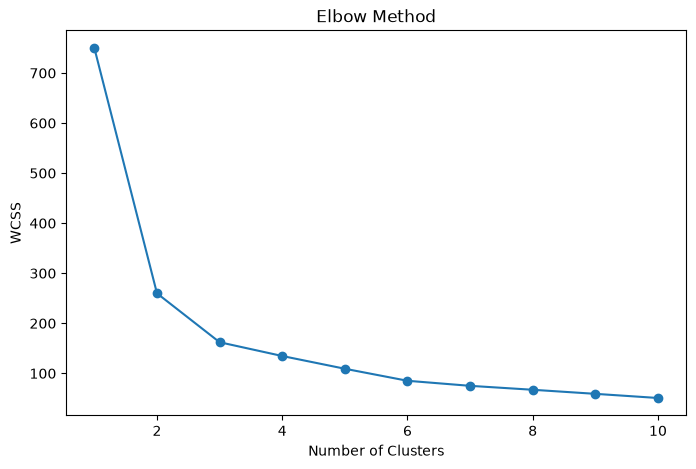

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

Step 7: Apply K-Means Clustering

In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

y_pred = kmeans.fit_predict(X_scaled)

print("\nCluster Labels:")
print(y_pred)


Cluster Labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 2 2 2
 2 2 1 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 1 2 2 2 2 2
 2 2]


Step 8: Add cluster labels to dataset

In [8]:
df = df.loc[X.index].copy()

df["Cluster"] = y_pred

print("\nDataset with Clusters:")
print(df.head())


Dataset with Clusters:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  Cluster  
0       0        0  
1       0        0  
2       0        0  
3       0        0  
4       0        0  


Step 9: Visualize Clusters

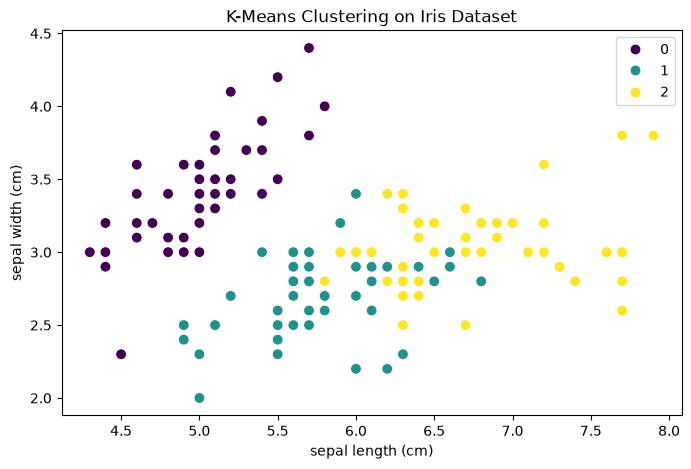

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X.iloc[:, 0],
    y=X.iloc[:, 1],
    hue=y_pred,
    palette="viridis",
    s=60
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])

plt.show()

Step 10: Display cluster count

In [10]:
print("\nNumber of Data Points in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())


Number of Data Points in Each Cluster:
Cluster
0    50
1    54
2    46
Name: count, dtype: int64
